# EfficientDet 실습 — 직접 해보기

과제 원본 코드(`4. EfficientDet 실습 [프로젝트].ipynb`)를 **흐름 단위로 묶어** 놓았다.
한 흐름을 끝까지 실행한 뒤, 그 아래 **✍️ 내 코멘트** 칸에 무엇을 했고 무엇을 알게 됐는지 적는다.

흐름마다 붙어 있는 칸
- **📖 코드 설명**: 코드가 한 줄 한 줄 무슨 일을 하는지
- **💡 생각해 볼 점**: 코드 리뷰할 때 짚어 볼 만한 부분 (원본 코드의 특이점, 개선할 여지)
- **✍️ 내 코멘트**: 직접 작성

**실행 전 확인**
- 오른쪽 위 커널이 **cv-4 EfficientDet (.venv)** 인지 확인한다.
- 이 노트북은 `cv-4/` 폴더에 있고, 흐름 1에서 `Yet-Another-EfficientDet-Pytorch/` 폴더로 들어간다. 그 뒤 모든 경로는 레포 폴더 기준이다.
- 코드는 원본 그대로다. 이 PC에서 그대로 안 되는 곳만 `# ☁️ 코랩용 (원본)`(주석 처리)과 `# 💻 노트북용`을 나란히 적어 두었다. 원본에 없는 셀은 첫 줄에 `# 💻 [추가]`라고 적었다.
- 학습(흐름 19~20)은 GPU로 합쳐서 10분 정도 걸린다. 영상 분석(흐름 10)도 3~4분 걸린다.

In [1]:
# 💻 [추가] 노트북용 셀 (원본에 없음): 커널이 .venv 파이썬이고 GPU가 보이는지 확인
import torch, sys
print("torch", torch.__version__, "| GPU 사용 가능:", torch.cuda.is_available())
print("파이썬 위치:", sys.executable)

torch 2.11.0+cu128 | GPU 사용 가능: True
파이썬 위치: C:\Users\LOQ5060\Desktop\cv-4\.venv\Scripts\python.exe


## 🗺️ 전체 흐름 한눈에

| 파트 | 흐름 | 하는 일 |
|---|---|---|
| A. 사전학습 모델로 이미지 추론 | 1~8 | 레포·가중치 준비 → 모델 만들기 → 전처리 → 추론 → 후처리 → 그리기 |
| B. 영상 분석 | 9~11 | 영상을 프레임 단위로 읽어 A와 같은 과정 반복 → 다시 영상으로 합치기 |
| C. 내 데이터로 학습 | 12~22 | 차량 데이터셋 준비·분석 → 레포 형식으로 변환 → 2단계 학습 → 평가 → 예측 |

**EfficientDet 한 장 추론 파이프라인** (파트 A가 이 순서 그대로다)

```
이미지 ─▶ preprocess ─▶ 모델 ─▶ postprocess ─▶ invert_affine ─▶ 그리기
         (정규화·        (백본 EfficientNet   (점수 거르기 + NMS)  (512 좌표를
          512 리사이즈·   → BiFPN → 박스/클래스 head)              원본 좌표로)
          패딩)
```

**YOLO 실습과 다른 점**: ultralytics YOLO는 `model.predict()` 한 줄이 위 과정을 전부 해 줬다.
이 레포는 각 단계를 함수로 따로 불러야 해서 코드는 길지만, 탐지 모델 안에서 무슨 일이 일어나는지 단계별로 볼 수 있다.

# 파트 A. 사전학습 모델로 이미지 추론

## 흐름 1. 레포 받고 작업 폴더로 이동하기
EfficientDet을 PyTorch로 구현한 오픈소스 레포를 받아, 그 폴더 안으로 들어간다.

**📖 코드 설명**
- `git clone ...`: 레포 전체(모델 코드 `backbone.py`, 유틸 `utils/`, 학습 `train.py` 등)를 내려받는다. ultralytics처럼 `pip install` 하는 패키지가 아니라 **레포 안의 파이썬 파일을 직접 import** 해서 쓰는 방식이다.
- `os.chdir(...)`: 현재 작업 폴더를 레포로 바꾼다. 그래야 `from backbone import ...` 같은 import와 `weights/`, `test/` 같은 상대 경로가 동작한다.
- `!`로 시작하는 줄은 셸 명령이다. 이 PC의 Jupyter에서는 Windows 명령창(cmd)으로 실행되어 `ls`, `pwd`, `unzip`, `grep` 같은 리눅스 명령이 없다. 그런 줄은 💻 노트북용으로 바꿨다.

**💡 생각해 볼 점**
- 레포를 미리 받아 두어서 `git clone`은 `fatal: destination path ... already exists`를 출력한다. 에러처럼 보이지만 "이미 있다"는 뜻이라 그냥 넘어가면 된다.
- `os.chdir` 셀을 두 번 실행하면 이미 레포 안이라 폴더를 못 찾는 에러가 난다. 처음부터 다시 하려면 커널을 재시작한다.

In [2]:
!git clone https://github.com/zylo117/Yet-Another-EfficientDet-Pytorch.git
# !pip install opencv-python matplotlib pycocotools

fatal: destination path 'Yet-Another-EfficientDet-Pytorch' already exists and is not an empty directory.


In [3]:
import os

os.chdir('Yet-Another-EfficientDet-Pytorch')
print("현재 디렉토리:", os.getcwd())

현재 디렉토리: C:\Users\LOQ5060\Desktop\cv-4\Yet-Another-EfficientDet-Pytorch


> ✍️ **내 코멘트**
>컴퓨터 환경에서 작동시키려고 조금 수정했습니다 if문을 사용해 이미 있으면 건너뛰는 과정 (데이터 로드중)

## 흐름 2. 사전학습 가중치 받기
COCO 데이터로 미리 학습된 EfficientDet-D0 가중치를 `weights/` 폴더에 받는다.

**📖 코드 설명**
- `efficientdet-d0.pth`: D0~D7 중 가장 작은 D0 모델의 학습된 숫자들(약 15MB). COCO 90개 클래스 번호로 학습되어 있다.
- `!mkdir -p weights` + `!wget URL -O 파일`은 "폴더 만들고, 주소에서 파일 받아 이 이름으로 저장"이라는 뜻이다.
- 노트북용 줄: `if not exist weights mkdir weights`는 "weights 폴더가 없으면 만든다", `curl -L URL -o 파일`은 wget과 같은 다운로드다(`-L`은 주소가 옮겨졌으면 따라가기).
- 주소의 레포 이름이 `Yet-Another-Efficient-Pytorch`(Det 빠짐)인데 오타가 아니라 실제로 가중치가 올라가 있는 곳이다.

In [4]:
# ☁️ 코랩용 (원본)
# !mkdir -p weights
# !wget https://github.com/zylo117/Yet-Another-Efficient-Pytorch/releases/download/1.0/efficientdet-d0.pth -O weights/efficientdet-d0.pth

# 💻 노트북용: Windows 명령창의 mkdir은 -p를 몰라 '-p' 폴더를 따로 만들고, wget은 없어서 Windows에 기본으로 있는 curl로 받는다
!if not exist weights mkdir weights
!curl -L https://github.com/zylo117/Yet-Another-Efficient-Pytorch/releases/download/1.0/efficientdet-d0.pth -o weights/efficientdet-d0.pth

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0                              0

  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0                              0
  0      0   0      0   0      0      0      0                              0

  0      0   0      0   0      0      0      0                              0
 19 15.12M  19  2.99M   0      0  1.68M      0   00:08   00:01   00:07  2.99M
 34 15.12M  34  5.28M   0      0  1.89M      0   00:07   00:02   00:05  2.63M
 49 15.12M  49  7.54M   0      0  1.99M      0   00:07   00:03   00:04  2.51M
 64 15.12M  64  9.82M   0      0  2.05M      0   00:07   00:0

> ✍️ **내 코멘트**
> 사전학습 가중치를 활용하기 위해 미리 가중치를 가져오는 작업이다
>

## 흐름 3. 모델 만들고 가중치 불러오기
모델 구조를 만들고, 받아 둔 가중치를 채워 넣은 뒤 추론 모드로 바꾼다.

**📖 코드 설명**
- `EfficientDetBackbone(compound_coef=0, num_classes=90)`: 모델의 **뼈대(구조)만** 만든다. 아직 숫자는 무작위다.
  - `compound_coef`: D0~D7 중 몇 번 모델인지. 숫자가 클수록 입력 크기·층 수·채널 수가 함께 커진다(Compound Scaling).
  - `num_classes=90`: COCO 클래스 번호가 1~90까지 있어서 90. (실제 물체는 80종이고 빈 번호가 10개 있다)
- `torch.load(..., map_location='cpu')`: 가중치 파일을 읽는다. GPU에서 저장된 파일이어도 일단 CPU 메모리로 읽어 온다.
- `load_state_dict(...)`: 읽어 온 숫자를 뼈대의 각 층에 이름표대로 채워 넣는다.
- `requires_grad_(False)`: 학습을 안 하니 기울기(gradient) 계산을 끈다 → 메모리·속도 절약.
- `eval()`: 추론 모드. BatchNorm·Dropout이 학습 때와 다르게(고정값으로) 동작한다.
- 출력되는 긴 구조는 크게 `bifpn`(특징 섞기), `regressor`(박스 위치 예측), `classifier`(클래스 예측), `backbone_net`(EfficientNet 특징 추출) 네 덩어리다.

| compound_coef | 모델 | 입력 크기 | 특징 |
|---|---|---|---|
| 0 | D0 | 512×512 | 가볍고 빠름, 정확도 낮음 |
| 1 | D1 | 640×640 | 중간 |
| 7 | D7 | 1536×1536 | 느리지만 정확도 높음 |

In [5]:
import torch
from backbone import EfficientDetBackbone
compound_coef = 0
model = EfficientDetBackbone(compound_coef=0, num_classes=90)

In [6]:
model.load_state_dict(torch.load(f'weights/efficientdet-d0.pth', map_location='cpu'))
model.requires_grad_(False)
model.eval()

EfficientDetBackbone(
  (bifpn): Sequential(
    (0): BiFPN(
      (conv6_up): SeparableConvBlock(
        (depthwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), groups=64, bias=False)
        )
        (pointwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
        )
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      )
      (conv5_up): SeparableConvBlock(
        (depthwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), groups=64, bias=False)
        )
        (pointwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
        )
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      )
      (conv4_up): SeparableConvBlock(
        (depthwise_conv): Conv2dStaticSamePadding(
      

**💡 생각해 볼 점**
- 바로 위에서 `compound_coef = 0` 변수를 만들어 놓고, 모델을 만들 때는 `compound_coef=0` 처럼 숫자를 직접 넣었다. 변수를 바꿔도 모델은 그대로 D0라서 실수하기 쉽다.

> ✍️ **내 코멘트**
>가장 빠른 D0 모델을 선택하고있다. (compound_coef = ?? <-- D??모델을 사용할거임)
>
> 또한 num_classes는 물체를 구분하는 개수를 설정해주는거다 <<우리는 가중치를 가져올거기 때문에 90이외의 숫자를 입력하면 오류가 발생
>
>출력되는 긴 구조는 크게 bifpn(특징 섞기), regressor(박스 위치 예측), classifier(클래스 예측), backbone_net(EfficientNet 특징 추출) 

## 흐름 4. 추론 설정값 정하기
앵커 모양, 점수 기준, NMS 기준, 클래스 이름 목록을 정한다.

**📖 코드 설명**
- **앵커(anchor)**: 모델이 박스를 예측할 때 기준으로 삼는 "미리 깔아 둔 박스". 모델은 박스를 처음부터 그리지 않고, 앵커를 **얼마나 옮기고 늘릴지**만 예측한다.
  - `anchor_ratios`: 앵커의 (가로, 세로) 배율 3종 → 정사각형, 가로로 긴 것, 세로로 긴 것
  - `anchor_scales`: 앵커 크기 3종 → 2⁰=1, 2^(1/3)≈1.26, 2^(2/3)≈1.59 배
  - 그래서 특징맵의 한 칸마다 3×3 = **9개 앵커**가 생긴다.
- `threshold = 0.2`: 클래스 점수가 0.2보다 낮은 예측은 버린다. (YOLO의 `conf`)
- `iou_threshold = 0.2`: NMS 기준. 같은 클래스 박스끼리 IoU가 0.2보다 많이 겹치면 중복으로 보고 점수 높은 것 하나만 남긴다. 낮을수록 더 많이 지워서, 가까이 붙은 물체를 놓칠 수 있다.
- `use_cuda`: GPU 사용 여부, `use_float16`: 16비트(반정밀도) 연산 여부
- `obj_list`: **리스트 위치 = 클래스 번호**. 중간중간 있는 `''`는 COCO에서 비어 있는 번호 자리다. 이 칸을 채워야 모델이 내놓는 번호와 이름이 맞는다. `len(obj_list)`가 90인지 확인한다.
- `force_input_size = None`: 입력 크기를 직접 정하지 않고 모델 기본값(D0는 512)을 쓴다는 뜻

In [7]:
compound_coef = 0
force_input_size = None  # set None to use default size
# img_path = 'bus.jpg'

# replace this part with your project's anchor config
anchor_ratios = [(1.0, 1.0), (1.4, 0.7), (0.7, 1.4)]
anchor_scales = [2 ** 0, 2 ** (1.0 / 3.0), 2 ** (2.0 / 3.0)]

threshold = 0.2
iou_threshold = 0.2

use_cuda = True
use_float16 = False

In [8]:
obj_list = ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light',
            'fire hydrant', '', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep',
            'cow', 'elephant', 'bear', 'zebra', 'giraffe', '', 'backpack', 'umbrella', '', '', 'handbag', 'tie',
            'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove',
            'skateboard', 'surfboard', 'tennis racket', 'bottle', '', 'wine glass', 'cup', 'fork', 'knife', 'spoon',
            'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut',
            'cake', 'chair', 'couch', 'potted plant', 'bed', '', 'dining table', '', '', 'toilet', '', 'tv',
            'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
            'refrigerator', '', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier',
            'toothbrush']

In [9]:
len(obj_list)

90

**💡 생각해 볼 점**
- 여기서 정한 `anchor_ratios`, `anchor_scales`는 흐름 3에서 모델을 만들 때 넘기지 않았다. 모델은 자기 기본값을 쓰는데 마침 값이 같아서 결과는 똑같다. 앵커를 바꾸려면 모델을 만들 때 `ratios=`, `scales=`로 넘겨야 한다. (흐름 22에서 다시 나온다)

> ✍️ **내 코멘트**
>
>탐지 대상 클래스 목록의 총 길이가 90개임을 확인하는 과정이다

## 흐름 5. 이미지 전처리하기
테스트 이미지를 모델 입력 모양 `(1, 3, 512, 512)` 텐서로 바꾼다.

**📖 코드 설명**
- `Image.open('test/img.png')`: 레포에 들어 있는 1920×1080 거리 사진을 확인한다.
- `input_sizes[compound_coef]`: D0~D7별 입력 크기 표에서 D0의 512를 꺼낸다.
- `preprocess(img_path, max_size=512)` 안에서 일어나는 일
  1. `cv2.imread`로 읽기 (BGR 순서)
  2. BGR→RGB, `/255`로 0~1, ImageNet 평균·표준편차로 정규화
  3. `aspectaware_resize_padding`: **비율을 유지**해서 긴 변을 512로 줄이고(1920×1080 → 512×288), 남는 아래쪽을 0으로 채워 512×512 정사각형을 만든다.
- 반환값 3개
  - `ori_imgs`: 원본 이미지 (나중에 결과를 그릴 때 사용)
  - `framed_imgs`: 모델에 넣을 512×512 이미지
  - `framed_metas`: 어떻게 바꿨는지 기록 `(new_w, new_h, old_w, old_h, padding_w, padding_h)` = `(512, 288, 1920, 1080, 0, 224)`. 224 = 512 − 288 (아래 패딩)
- `torch.stack([...], 0)`: 이미지 리스트를 **배치 차원**으로 쌓는다 → `(1, 512, 512, 3)`. `.cuda()`는 GPU로 올리기.
- `.permute(0, 3, 1, 2)`: `(배치, 높이, 너비, 채널)` → `(배치, 채널, 높이, 너비)`. PyTorch 모델은 채널이 앞에 와야 한다.

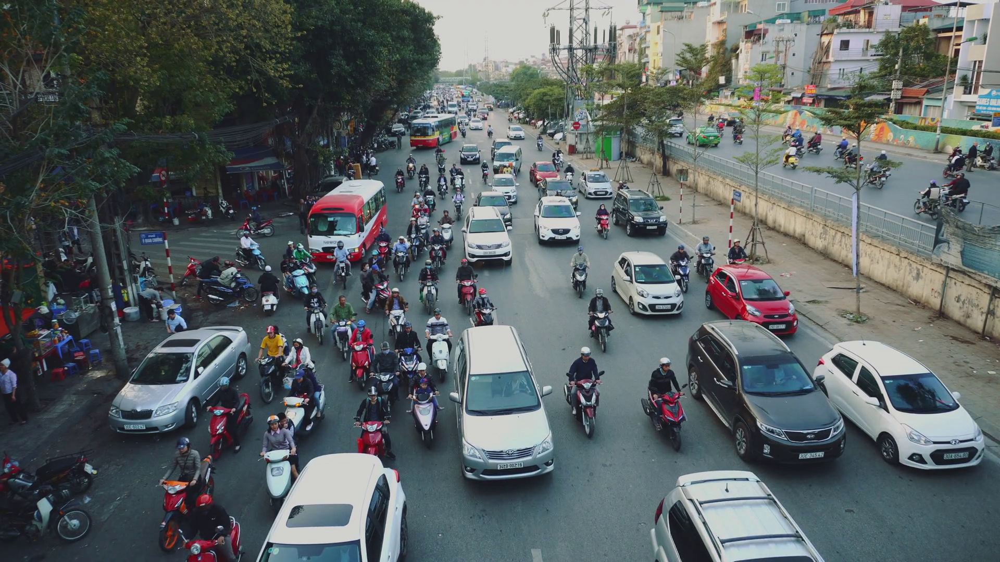

In [10]:
from PIL import Image
Image.open('test/img.png')

In [11]:
from utils.utils import preprocess, invert_affine, postprocess, STANDARD_COLORS, standard_to_bgr, get_index_label, plot_one_box

img_path = 'test/img.png'
color_list = standard_to_bgr(STANDARD_COLORS)
input_sizes = [512, 640, 768, 896, 1024, 1280, 1280, 1536, 1536]
input_size = input_sizes[compound_coef] if force_input_size is None else force_input_size
ori_imgs, framed_imgs, framed_metas = preprocess(img_path, max_size=input_size)
if use_cuda:
    x = torch.stack([torch.from_numpy(fi).cuda() for fi in framed_imgs], 0)
else:
    x = torch.stack([torch.from_numpy(fi) for fi in framed_imgs], 0)
x = x.to(torch.float32 if not use_float16 else torch.float16).permute(0, 3, 1, 2)

In [12]:
ori_imgs[0].shape, framed_imgs[0].shape

((1080, 1920, 3), (512, 512, 3))

In [13]:
framed_metas

[(512, 288, 1920, 1080, 0, 224)]

**💡 생각해 볼 점**
- YOLO(letterbox)는 이미지를 가운데 두고 위아래에 패딩을 넣지만, 여기는 **왼쪽 위에 붙이고 오른쪽·아래만** 채운다. 그래서 나중에 좌표를 되돌릴 때 패딩을 빼지 않고 배율만 나누면 된다(흐름 8 `invert_affine`).
- 직접 확인: `x.shape`를 출력해 보면 `(1, 3, 512, 512)`가 나와야 한다.

> ✍️ **내 코멘트**
>12셀 원래 이미지 크기가 1080X1920이였으나 D0모델 크기에 맞게 512X512로 변경해준 모습이다
>
> 또한 밑에는 이미지 비율을 유지하며 맞추는 과정에서 생긴 여백(패딩 224px)과 원본 좌표 복원을 위한 메타 정보입니다

## 흐름 6. 모델에 넣고 출력 4가지 보기
전처리한 텐서를 모델에 넣으면 `features, regression, classification, anchors` 4가지가 나온다.

**📖 코드 설명**
- `model.cuda()`: 모델도 GPU로 올린다. 입력 `x`와 모델이 **같은 장치**에 있어야 계산이 된다.
- `with torch.no_grad():`: 이 블록 안에서는 기울기를 저장하지 않는다(추론 전용).
- 출력 4가지

| 이름 | 모양 | 뜻 |
|---|---|---|
| `features` | 5개 특징맵 | BiFPN을 거친 P3~P7 특징맵. 64×64, 32×32, 16×16, 8×8, 4×4 (512를 8·16·32·64·128로 나눈 크기), 채널 64 |
| `regression` | (1, 49104, 4) | 앵커마다 얼마나 옮기고 늘릴지 (dy, dx, dh, dw) |
| `classification` | (1, 49104, 90) | 앵커마다 90개 클래스 각각의 확률 |
| `anchors` | (1, 49104, 4) | 기준 박스들의 좌표 |

- **49104개는 어디서?** 특징맵 칸 수 × 칸당 앵커 9개 = (64² + 32² + 16² + 8² + 4²) × 9 = 5456 × 9 = 49104
- 큰 특징맵(64×64, 칸이 촘촘함)은 **작은 물체**, 작은 특징맵(4×4)은 **큰 물체**를 맡는다.
- 원본 셀의 `regression[0].shape`은 배치의 첫 장이라 `(49104, 4)`로 나온다.

In [14]:
if use_cuda:
    model = model.cuda()
if use_float16:
    model = model.half()
with torch.no_grad():
    features, regression, classification, anchors = model(x)

In [15]:
features[0].shape, regression[0].shape, classification.shape, anchors.shape

(torch.Size([1, 64, 64, 64]),
 torch.Size([49104, 4]),
 torch.Size([1, 49104, 90]),
 torch.Size([1, 49104, 4]))

In [16]:
len(features)

5

In [17]:
features[0].shape, features[1].shape, features[2].shape, features[3].shape, features[4].shape

(torch.Size([1, 64, 64, 64]),
 torch.Size([1, 64, 32, 32]),
 torch.Size([1, 64, 16, 16]),
 torch.Size([1, 64, 8, 8]),
 torch.Size([1, 64, 4, 4]))

**💡 생각해 볼 점**
- 직접 계산해 보기: `(64*64 + 32*32 + 16*16 + 8*8 + 4*4) * 9` 를 셀에서 실행하면 49104가 나온다.

> ✍️ **내 코멘트**
>
>

## 흐름 7. 후처리해서 박스로 바꾸기
49104개의 앵커 예측을 사람이 읽을 수 있는 **박스 좌표 · 클래스 · 점수**로 바꾼다.

**📖 코드 설명**
- `BBoxTransform()`: 앵커 + regression → 실제 박스 `(x1, y1, x2, y2)`
  - 중심 = 앵커 중심 + (dy, dx) × 앵커 크기
  - 크기 = 앵커 크기 × exp(dh, dw)
- `ClipBoxes()`: 이미지(512×512) 밖으로 나간 좌표를 경계에 맞춰 자른다.
- `postprocess(...)` 안에서 일어나는 일
  1. 앵커마다 90개 클래스 중 **가장 높은 점수**를 고르고, `threshold`(0.2)를 넘는 앵커만 남긴다.
  2. 클래스별로 NMS(`batched_nms`, `iou_threshold`)를 해서 겹치는 박스를 지운다.
  3. 이미지마다 `{'rois': 박스, 'class_ids': 클래스 번호, 'scores': 점수}` 딕셔너리를 만든다.
- 결과: 49104개 → 수십 개(원본 실행 기준 37개). 단, 이 좌표는 아직 **512×512 입력 기준**이다.

In [18]:
from utils.utils import postprocess
from efficientdet.utils import BBoxTransform, ClipBoxes

with torch.no_grad():
    features, regression, classification, anchors = model(x)
    regressBoxes = BBoxTransform() # 모델이 예측한 regression 값을 실제 bounding box 좌표로 변환
    clipBoxes = ClipBoxes()        # 모델이 예측한 object의 box가 이미지 범위를 벗어나지 않도록 조정
    out = postprocess(x,
                      anchors, regression, classification,
                      regressBoxes, clipBoxes,
                      threshold, iou_threshold)

In [19]:
out

[{'rois': array([[333.9106    , 239.92058   , 424.38052   , 287.47403   ],
         [314.5778    , 129.69664   , 351.32883   , 163.34978   ],
         [350.18918   , 165.4527    , 433.36374   , 241.53989   ],
         [130.6782    , 232.14676   , 207.67924   , 287.59213   ],
         [362.0041    , 135.1465    , 408.65985   , 169.68913   ],
         [ 56.523476  , 167.49417   , 129.53165   , 224.73514   ],
         [414.8751    , 173.18457   , 506.78836   , 242.55646   ],
         [  0.8899746 , 233.43506   ,  48.700165  , 277.26663   ],
         [ 80.5062    , 246.80457   , 122.74743   , 286.69556   ],
         [232.98915   , 165.0869    , 285.26852   , 247.47136   ],
         [155.37982   ,  93.800156  , 196.91263   , 136.37265   ],
         [330.41754   , 184.252     , 350.99792   , 229.17503   ],
         [290.06723   , 180.9333    , 309.02994   , 222.60262   ],
         [236.92595   , 112.800186  , 263.35764   , 136.59938   ],
         [316.6743    ,  98.80613   , 343.58554   , 12

In [20]:
out[0]['rois'].shape, out[0]['class_ids'].shape, out[0]['scores'].shape

((37, 4), (37,), (37,))

**💡 생각해 볼 점**
- 흐름 6에서 이미 모델을 돌렸는데 여기서 `model(x)`를 한 번 더 돌린다. 결과는 같으니 흐름 6의 출력을 그대로 써도 된다.
- `threshold`를 0.5로 올리고 다시 실행해 보면 탐지 개수가 어떻게 바뀌는지 직접 볼 수 있다.

> ✍️ **내 코멘트**
>
>

## 흐름 8. 원본 크기로 되돌리고 결과 그리기
박스를 원본 1920×1080 좌표로 되돌린 뒤, 원본 이미지에 그려 파일로 저장하고 화면에 띄운다.

**📖 코드 설명**
- `display(preds, imgs, imshow, imwrite)`: 이미지마다
  - 탐지가 0개면 건너뛰고(`continue`), 원본을 복사한 뒤
  - 박스마다 좌표를 정수로 바꾸고, `class_ids`로 `obj_list`에서 이름을, `scores`에서 점수를 꺼내
  - 레포 유틸 `plot_one_box`로 박스 + 라벨을 그린다. 색은 클래스 이름별로 정해진다.
  - `imshow=False`라 창은 안 띄우고, `imwrite=True`라 `test/img_inferred_d0_this_repo_0.jpg`로 저장한다.
- `invert_affine(framed_metas, out)`: 512 기준 좌표를 원본 기준으로 되돌린다. x는 `512/1920`으로, y는 `288/1080`으로 나눈다(줄인 배율만큼 다시 키우기).
- 마지막 셀: 저장된 파일을 PIL로 열어 matplotlib으로 띄운다.

In [21]:
import cv2
def display(preds, imgs, imshow=True, imwrite=False):
    for i in range(len(imgs)):
        if len(preds[i]['rois']) == 0:
            continue

        imgs[i] = imgs[i].copy()

        for j in range(len(preds[i]['rois'])):
            x1, y1, x2, y2 = preds[i]['rois'][j].astype(np.int32)
            obj = obj_list[preds[i]['class_ids'][j]]
            score = float(preds[i]['scores'][j])
            plot_one_box(imgs[i], [x1, y1, x2, y2], label=obj,score=score,color=color_list[get_index_label(obj, obj_list)])


        if imshow:
            cv2.imshow('img', imgs[i])
            cv2.waitKey(0)

        if imwrite:
            cv2.imwrite(f'test/img_inferred_d{compound_coef}_this_repo_{i}.jpg', imgs[i])

    return f'test/img_inferred_d{compound_coef}_this_repo_'

In [22]:
import numpy as np
out = invert_affine(framed_metas, out)
img_path = display(out, ori_imgs, imshow=False, imwrite=True)

In [23]:
img_path

'test/img_inferred_d0_this_repo_'

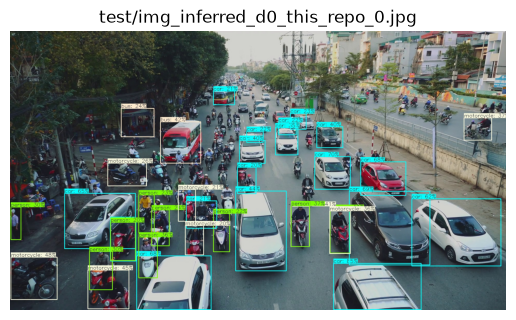

In [24]:
from PIL import Image
import matplotlib.pyplot as plt

img_path = f"{img_path}0.jpg"  # 파일 확장자에 따라 수정 가능

img = Image.open(img_path)

# 이미지 출력
plt.imshow(img)
plt.axis('off')  # 축 제거
plt.title(img_path)
plt.show()

**💡 생각해 볼 점**
- `display` 함수 안에서 `np`를 쓰는데 `import numpy as np`는 다음 셀에 있다. 파이썬은 함수를 **정의할 때가 아니라 호출할 때** 이름을 찾기 때문에 동작은 하지만, import는 맨 위에 두는 게 안전하다.
- `img_path`라는 변수 이름을 입력 경로 → 저장 경로 앞부분 → 저장 파일 경로로 계속 바꿔 쓴다. 셀을 순서 없이 다시 실행하면 경로가 꼬인다.
- 레포에 들어 있는 `test/img_inferred_d0_official.jpg`(공식 결과)와 비교해 보면 재미있다.

> ✍️ **내 코멘트**
>
>

# 파트 B. 영상 분석
영상은 이미지의 연속이라, 프레임마다 파트 A와 **똑같은 과정**을 반복하면 된다.

## 흐름 9. 영상 준비하고 모델 다시 불러오기
분석할 영상과 저장 위치를 정하고, 레포의 영상 추론 스크립트처럼 모델을 처음부터 다시 만든다.

**📖 코드 설명**
- `video_src`: 문자열이면 영상 파일, 정수(`0`)면 웹캠을 연다.
- `output_dir`: 박스를 그린 프레임 이미지를 저장할 폴더, `output_video_path`: 마지막에 합칠 영상 파일
- `force_input_size = 512`: 입력 크기를 512로 고정
- 모델 생성 → 가중치 로드 → `requires_grad_(False)` → `eval()` → GPU로: 흐름 3, 6과 같다.
- 새 `display`: 이번엔 `plot_one_box` 대신 `cv2.rectangle`(박스)과 `cv2.putText`(글자)로 직접 그린다. 색 `(255, 255, 0)`은 OpenCV가 BGR 순서라 **하늘색**이다.
- `regressBoxes`, `clipBoxes`를 루프 밖에서 한 번만 만들어 둔다.

In [ ]:
# ☁️ 코랩용 (원본)
# !pwd
# 💻 노트북용: Windows 명령창에는 pwd가 없다 → 파이썬으로 현재 폴더를 본다
os.getcwd()

In [27]:
# ☁️ 코랩용 (원본)
# os.path.exists('soccer.mp4')
# 💻 노트북용: 받은 영상 파일은 soccer.gif (원본 Colab 실행 기록에도 이 셀은 False였다)
os.path.exists('soccer.gif')

True

In [28]:
# Core Author: Zylo117
# Script's Author: winter2897

"""
Simple Inference Script of EfficientDet-Pytorch for detecting objects on webcam
"""
import time
import torch
import cv2
import numpy as np
from torch.backends import cudnn
from backbone import EfficientDetBackbone
from efficientdet.utils import BBoxTransform, ClipBoxes
from utils.utils import preprocess, invert_affine, postprocess, preprocess_video

# Video's path
# ☁️ 코랩용 (원본)
# video_src = 'soccer.mp4'  # set int to use webcam, set str to read from a video file
# 💻 노트북용: 받은 영상 파일은 soccer.gif (OpenCV는 gif도 영상처럼 읽는다)
video_src = 'soccer.gif'  # set int to use webcam, set str to read from a video file
# output_dir = './output_soccer_frames'
# ☁️ 코랩용 (원본)
# output_dir = '/content/Yet-Another-EfficientDet-Pytorch/output_soccer_frames'
# output_video_path = '/content/Yet-Another-EfficientDet-Pytorch/output_soccer.mp4'
# 💻 노트북용: /content/는 Colab에만 있는 폴더라 레포 기준 상대 경로로
output_dir = './output_soccer_frames'
output_video_path = './output_soccer.mp4'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

compound_coef = 0
force_input_size = 512  # set None to use default size

threshold = 0.2
iou_threshold = 0.2

use_cuda = True
use_float16 = False

obj_list = ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light',
            'fire hydrant', '', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep',
            'cow', 'elephant', 'bear', 'zebra', 'giraffe', '', 'backpack', 'umbrella', '', '', 'handbag', 'tie',
            'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove',
            'skateboard', 'surfboard', 'tennis racket', 'bottle', '', 'wine glass', 'cup', 'fork', 'knife', 'spoon',
            'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut',
            'cake', 'chair', 'couch', 'potted plant', 'bed', '', 'dining table', '', '', 'toilet', '', 'tv',
            'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
            'refrigerator', '', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier',
            'toothbrush']

input_sizes = [512, 640, 768, 896, 1024, 1280, 1280, 1536, 1536]
input_size = input_sizes[compound_coef] if force_input_size is None else force_input_size

# load model
model = EfficientDetBackbone(compound_coef=compound_coef, num_classes=len(obj_list))
model.load_state_dict(torch.load(f'weights/efficientdet-d{compound_coef}.pth'))
model.requires_grad_(False)
model.eval()

EfficientDetBackbone(
  (bifpn): Sequential(
    (0): BiFPN(
      (conv6_up): SeparableConvBlock(
        (depthwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), groups=64, bias=False)
        )
        (pointwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
        )
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      )
      (conv5_up): SeparableConvBlock(
        (depthwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), groups=64, bias=False)
        )
        (pointwise_conv): Conv2dStaticSamePadding(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1))
        )
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      )
      (conv4_up): SeparableConvBlock(
        (depthwise_conv): Conv2dStaticSamePadding(
      

In [29]:
if use_cuda:
    model = model.cuda()
if use_float16:
    model = model.half()

In [30]:
# function for display
def display(preds, imgs):
    for i in range(len(imgs)):
        if len(preds[i]['rois']) == 0:
            return imgs[i]

        for j in range(len(preds[i]['rois'])):
            (x1, y1, x2, y2) = preds[i]['rois'][j].astype(np.int64)
            cv2.rectangle(imgs[i], (x1, y1), (x2, y2), (255, 255, 0), 2)
            obj = obj_list[preds[i]['class_ids'][j]]
            score = float(preds[i]['scores'][j])

            cv2.putText(imgs[i], '{}, {:.3f}'.format(obj, score),
                        (x1, y1 + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                        (255, 255, 0), 1)

        return imgs[i]
# Box
regressBoxes = BBoxTransform()
clipBoxes = ClipBoxes()

**💡 생각해 볼 점**
- 파트 A에서 이미 만든 모델과 `obj_list`를 그대로 다시 만든다. 레포의 `efficientdet_test_videos.py` 스크립트를 통째로 붙여 넣어서 생긴 중복이다.
- 새 `display`는 반복문 **안에서** `return` 한다. 이미지가 한 장일 때는 상관없지만, 여러 장이면 첫 장만 처리하고 끝난다.

> ✍️ **내 코멘트**
>
>

## 흐름 10. 프레임마다 탐지하고 저장하기
영상을 한 프레임씩 읽어 탐지하고, 박스를 그린 프레임을 이미지 파일로 저장한다.

**📖 코드 설명**
- `cv2.VideoCapture(video_src)`: 영상을 연다.
- `ret, frame = cap.read()`: 다음 프레임을 읽는다. 영상이 끝나면 `ret`이 `False` → `break`
- `preprocess_video(frame, ...)`: 파일 경로 대신 **프레임 배열**을 받는 전처리. 나머지는 `preprocess`와 같다.
- 텐서 만들기 → 모델 → `postprocess` → `invert_affine` → `display`: 파트 A와 똑같은 순서
- `f'frame_{frame_idx:05d}.jpg'`: 번호를 다섯 자리로 0을 채워(00000, 00001, …) 이름순 정렬이 곧 시간순이 되게 한다.
- `cap.release()`: 영상 파일을 닫는다.

In [31]:
# Video capture
cap = cv2.VideoCapture(video_src)
frame_idx = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # frame preprocessing
    ori_imgs, framed_imgs, framed_metas = preprocess_video(frame, max_size=input_size)

    if use_cuda:
        x = torch.stack([torch.from_numpy(fi).cuda() for fi in framed_imgs], 0)
    else:
        x = torch.stack([torch.from_numpy(fi) for fi in framed_imgs], 0)

    x = x.to(torch.float32 if not use_float16 else torch.float16).permute(0, 3, 1, 2)

    # model predict
    with torch.no_grad():
        features, regression, classification, anchors = model(x)

        out = postprocess(x,
                        anchors, regression, classification,
                        regressBoxes, clipBoxes,
                        threshold, iou_threshold)

    # result
    out = invert_affine(framed_metas, out)
    img_show = display(out, ori_imgs)

    # show frame by frame
    img_show = display(out, ori_imgs)

    # 프레임 저장
    frame_path = os.path.join(output_dir, f'frame_{frame_idx:05d}.jpg')
    cv2.imwrite(frame_path, img_show)
    frame_idx += 1


cap.release()
# cv2.destroyAllWindows()

In [ ]:
# ☁️ 코랩용 (원본)
# !ls -l
# 💻 노트북용: Windows 명령창에는 ls가 없다 → 파이썬으로 폴더 내용을 본다
for name in sorted(os.listdir('.')):
    print(name)

In [33]:
os.listdir(output_dir)[:10]

['frame_00000.jpg',
 'frame_00001.jpg',
 'frame_00002.jpg',
 'frame_00003.jpg',
 'frame_00004.jpg',
 'frame_00005.jpg',
 'frame_00006.jpg',
 'frame_00007.jpg',
 'frame_00008.jpg',
 'frame_00009.jpg']

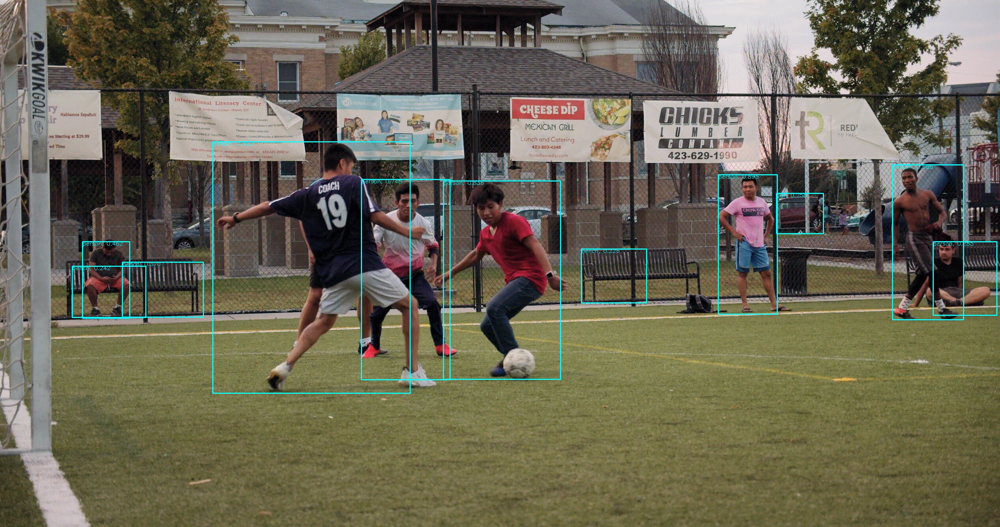

In [34]:
img = Image.open(os.path.join(output_dir, 'frame_00004.jpg'))
img

**💡 생각해 볼 점**
- `display`를 **두 번** 호출한다. 같은 이미지에 박스와 글자가 두 번 겹쳐 그려진다(같은 자리라 눈에는 잘 안 띈다).
- `preprocess_video`의 기본 평균·표준편차는 `(0.406, 0.456, 0.485)`로, `preprocess`의 `(0.485, 0.456, 0.406)`과 순서가 반대다. 그런데 둘 다 똑같이 BGR→RGB로 뒤집은 뒤 빼기 때문에, 영상 쪽은 R과 B 채널에 평균이 바뀌어 적용된다(레포 코드의 특이점).
- `os.listdir` 결과는 이름순이 아니라 뒤죽박죽이다. 그래서 다음 흐름에서 `sorted`로 정렬한다.

> ✍️ **내 코멘트**
>
>

## 흐름 11. 프레임을 다시 영상으로 합치기
저장한 프레임 이미지들을 순서대로 이어 붙여 mp4 영상을 만든다.

**📖 코드 설명**
- `sorted(...)`: 파일 이름순 = 프레임 순서로 정렬
- 첫 프레임을 읽어 영상의 가로·세로 크기를 정한다.
- `cv2.VideoWriter_fourcc(*'mp4v')`: mp4 코덱 지정
- `cv2.VideoWriter(경로, 코덱, 20.0, (가로, 세로))`: 초당 20프레임 영상 파일을 연다.
- `out_video.write(img)`: 한 장씩 붙인다. `release()`로 파일을 마무리해야 영상이 정상 저장된다.

In [35]:
# 🔄 이미지들을 비디오로 합치기
images = sorted([img for img in os.listdir(output_dir) if img.endswith(".jpg")])
first_frame = cv2.imread(os.path.join(output_dir, images[0]))
height, width, _ = first_frame.shape

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_video = cv2.VideoWriter(output_video_path, fourcc, 20.0, (width, height))  # 20fps

for image_file in images:
    img = cv2.imread(os.path.join(output_dir, image_file))
    out_video.write(img)

out_video.release()
print(f"✅ 영상 생성 완료: {output_video_path}")

✅ 영상 생성 완료: ./output_soccer.mp4


In [36]:
os.path.exists(output_video_path)

True

**💡 생각해 볼 점**
- fps를 20으로 고정했다. 원본 영상 fps가 다르면 결과 영상이 빨라지거나 느려진다. `soccer.gif`는 약 23fps라 결과 영상이 조금 느리게 재생된다. `cap.get(cv2.CAP_PROP_FPS)`로 원본 fps를 읽어 쓰면 된다.
- 프레임을 jpg로 모두 저장했다가 다시 읽는 대신, 흐름 10의 루프 안에서 바로 `VideoWriter`에 쓰면 디스크와 시간을 아낄 수 있다.
- 만들어진 `output_soccer.mp4`는 레포 폴더에 있다. 직접 열어서 확인해 보자.

> ✍️ **내 코멘트**
>
>

# 파트 C. 내 데이터(차량)로 학습하기
Kaggle 차량 탐지 데이터셋: https://www.kaggle.com/datasets/pkdarabi/vehicle-detection-image-dataset

Roboflow에서 **COCO 형식**으로 내보낸 데이터로, 흑백 버전(`Apply_Grayscale`, v9i)과 컬러 버전(`No_Apply_Grayscale`, v8i) 두 가지가 들어 있다.

| 포맷 | 라벨 파일 | 좌표 형식 |
|---|---|---|
| **COCO** (이번 실습) | JSON 하나에 전체 이미지 라벨 | x, y, width, height (픽셀, 왼쪽 위 기준) |
| VOC | 이미지마다 XML | xmin, ymin, xmax, ymax |
| YOLO (지난 실습) | 이미지마다 txt | class, x_center, y_center, w, h (0~1 정규화) |

## 흐름 12. 데이터셋 풀고 한 장 확인하기
압축을 풀고, COCO 라벨 JSON을 읽어 이미지 한 장에 정답 박스를 그려 본다.

**📖 코드 설명**
- COCO JSON의 세 부분
  - `images`: 이미지마다 `id`, `file_name`, 크기
  - `annotations`: 박스마다 `image_id`(어느 이미지인지), `category_id`(클래스), `bbox` `[x, y, w, h]`
  - `categories`: `id` ↔ `name`
- `show_single_coco_image(...)`
  1. JSON을 읽고 `image_index`번째 이미지의 `id`와 파일명을 꺼낸다.
  2. `annotations` 중 그 `image_id`인 것만 골라낸다.
  3. `{id: name}` 사전을 만들어 클래스 이름을 찾는다.
  4. `bbox`는 왼쪽 위 + 너비·높이라서 오른쪽 아래는 `(x + w, y + h)`로 계산해 초록 박스를 그린다.
  5. OpenCV(BGR) → matplotlib(RGB)로 색 순서를 바꿔 띄운다.
- `!unzip 파일 -d 폴더`는 "압축을 이 폴더에 푼다"는 뜻이다.

In [37]:
import os
import json
import cv2
import matplotlib.pyplot as plt

def show_single_coco_image(
    coco_json_path,
    image_dir,
    image_index=0  # 시각화할 이미지 순서 (0부터 시작)
):
    # Load annotation JSON
    with open(coco_json_path, 'r') as f:
        coco = json.load(f)

    # Map image_id to image metadata
    image_info = coco['images'][image_index]
    image_id = image_info['id']
    file_name = image_info['file_name']
    img_path = os.path.join(image_dir, file_name)

    # Load image
    img = cv2.imread(img_path)
    if img is None:
        print(f"이미지를 불러올 수 없습니다: {img_path}")
        return

    # Index annotations for this image
    anns = [ann for ann in coco['annotations'] if ann['image_id'] == image_id]
    cat_id_to_name = {cat['id']: cat['name'] for cat in coco['categories']}

    # Draw bounding boxes
    for ann in anns:
        x, y, w, h = map(int, ann['bbox'])
        category_id = ann['category_id']
        label = cat_id_to_name.get(category_id, str(category_id))

        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(img, label, (x, y - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

    # Convert BGR to RGB for matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Show image
    plt.figure(figsize=(10, 10))
    plt.imshow(img_rgb)
    plt.title(file_name)
    plt.axis('off')
    plt.show()

In [ ]:
# ☁️ 코랩용 (원본)
# !ls -l
# 💻 노트북용: Windows 명령창에는 ls가 없다 → 파이썬으로 폴더 내용을 본다
for name in sorted(os.listdir('.')):
    print(name)

In [ ]:
# ☁️ 코랩용 (원본)
# !pwd
# 💻 노트북용: Windows 명령창에는 pwd가 없다 → 파이썬으로 현재 폴더를 본다
os.getcwd()

In [ ]:
# ☁️ 코랩용 (원본)
# !unzip ./datasets/archive.zip -d ./datasets/car_detect
# 💻 노트북용: Windows 명령창에는 unzip이 없다 → 파이썬 zipfile로 같은 폴더에 푼다
import zipfile
with zipfile.ZipFile('./datasets/archive.zip') as z:
    z.extractall('./datasets/car_detect')
print(os.listdir('./datasets/car_detect'))

In [41]:
show_single_coco_image(
    coco_json_path='./datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/test/_annotations.coco.json',
    image_dir='./datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/test',
    image_index=0  # 첫 번째 이미지 시각화
)

FileNotFoundError: [Errno 2] No such file or directory: './datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/test/_annotations.coco.json'

**💡 생각해 볼 점**
- `image_index`를 1, 2, 3으로 바꿔 여러 장을 보면 어떤 장면(도로, 고가도로 등)과 어떤 크기의 차가 많은지 감이 온다.
- 같은 함수로 `Apply_Grayscale` 폴더를 넣어 흑백 버전도 비교해 보자.

> ✍️ **내 코멘트**
>
>

## 흐름 13. 데이터셋의 평균·표준편차 구하기
정규화에 쓸 RGB 채널별 평균과 표준편차를 이 데이터셋에서 직접 계산한다.

**📖 코드 설명**
- **왜 필요한가**: 모델 입력은 `(픽셀 − 평균) / 표준편차`로 정규화한다. 기본값은 ImageNet 값 `(0.485, 0.456, 0.406)`인데, 데이터 색감이 많이 다르면 직접 계산한 값을 쓴다.
- `glob(... '*.jpg')`: 폴더의 jpg 경로를 모두 모은다. `max_images`가 있으면 앞에서부터 그만큼만
- `tqdm(...)`: 진행 막대를 보여 준다.
- 이미지마다: BGR→RGB, `/255`로 0~1, `np.mean(img, axis=(0, 1))`로 **세로·가로 방향을 다 평균**해 채널(R, G, B)별 값 3개를 얻는다.
- 모든 이미지의 값을 다시 평균해 최종 평균·표준편차를 낸다.

In [ ]:
import os
import cv2
import numpy as np
from glob import glob
from tqdm import tqdm

def compute_mean_std(image_dir, max_images=None):
    image_paths = sorted(glob(os.path.join(image_dir, '*.jpg')))
    if max_images:
        image_paths = image_paths[:max_images]

    means = []
    stds = []

    for path in tqdm(image_paths, desc="Computing mean/std"):
        img = cv2.imread(path)  # BGR
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = img / 255.0
        means.append(np.mean(img, axis=(0, 1)))
        stds.append(np.std(img, axis=(0, 1)))

    mean = np.mean(means, axis=0)
    std = np.mean(stds, axis=0)

    print(f"✅ RGB mean: {mean.tolist()}")
    print(f"✅ RGB std : {std.tolist()}")
    return mean.tolist(), std.tolist()

In [ ]:
compute_mean_std('./datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/train', max_images=500)  # 샘플 500장 기준

**💡 생각해 볼 점**
- 표준편차를 "이미지별 표준편차의 평균"으로 구했다. 전체 픽셀을 한꺼번에 놓고 구한 표준편차와는 조금 다르다(이미지 사이의 밝기 차이가 빠진다). 정규화용으로는 충분한 근사다.
- 여기서는 **컬러(No_Apply)** 데이터로 계산했는데, 흐름 16에서 실제로 학습에 쓰는 건 **흑백(Apply_Grayscale)** 데이터다. 학습할 데이터로 계산하는 게 맞다.
- 흐름 13 결과의 R, G, B 값이 거의 같다 → 색이 거의 없는(회색에 가까운) 영상이라는 뜻이다.

> ✍️ **내 코멘트**
>
>

## 흐름 14. 박스 모양 분석해서 앵커 정하기
정답 박스들의 가로세로 비율과 크기 분포를 보고, 이 데이터에 맞는 앵커 비율·크기를 추천받는다.

**📖 코드 설명**
- **왜 필요한가**: 앵커가 실제 물체 모양과 비슷할수록 모델이 조금만 고쳐도 되니 학습이 쉽다. COCO 기본 앵커는 사람·동물·물건 전반에 맞춰져 있다.
- 박스마다
  - 비율 `ratio = w / h` (1보다 작으면 세로로 긴 박스)
  - 크기 `scale = √(w × h)` (면적을 한 변 길이로 바꾼 값)
- 그래프 3개: 비율 분포 / 크기 분포 / 크기의 log 분포 (작은 물체가 많으면 log로 봐야 모양이 잘 보인다)
- `np.percentile(ratios, [20, 50, 80])`: 하위 20%·중앙·상위 20% 지점의 비율 3개 → 추천 앵커 비율
- 크기도 20/50/80% 지점을 구하고, 중앙값으로 나눠 상대 배수로 만든다 → 추천 앵커 크기
- 마지막에 샘플 10개 이상인 카테고리별 중앙 비율을 많은 순으로 5개 출력한다.

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

def analyze_bbox_ratios_and_scales(coco_json_path, show_plots=True):

    with open(coco_json_path, 'r') as f:
        coco = json.load(f)

    # 바운딩 박스 정보 추출
    widths, heights, areas = [], [], []
    category_stats = defaultdict(list)  # 카테고리별 통계

    # 카테고리 이름 매핑
    cat_id_to_name = {cat['id']: cat['name'] for cat in coco['categories']}

    for ann in coco['annotations']:
        x, y, w, h = ann['bbox']
        if w > 0 and h > 0:  # 유효한 바운딩 박스만
            widths.append(w)
            heights.append(h)
            areas.append(w * h)

            # 카테고리별 분석을 위해
            cat_name = cat_id_to_name.get(ann['category_id'], 'unknown')
            category_stats[cat_name].append((w, h))

    widths = np.array(widths)
    heights = np.array(heights)
    areas = np.array(areas)

    # 1. Aspect Ratios 계산
    ratios = widths / heights

    # 2. Scales 계산 (면적의 제곱근)
    scales = np.sqrt(areas)

    # 3. 시각화
    if show_plots:
        plt.figure(figsize=(15, 5))

        # Aspect Ratios 히스토그램
        plt.subplot(1, 3, 1)
        plt.hist(ratios, bins=50, alpha=0.7, edgecolor='black')
        plt.axvline(np.median(ratios), color='red', linestyle='--',
                   label=f'Median: {np.median(ratios):.2f}')
        plt.xlabel('Aspect Ratio (W/H)')
        plt.ylabel('Frequency')
        plt.title('Distribution of Aspect Ratios')
        plt.legend()
        plt.grid(True, alpha=0.3)

        # Scales 히스토그램
        plt.subplot(1, 3, 2)
        plt.hist(scales, bins=50, alpha=0.7, edgecolor='black')
        plt.axvline(np.median(scales), color='red', linestyle='--',
                   label=f'Median: {np.median(scales):.1f}')
        plt.xlabel('Scale (sqrt of area)')
        plt.ylabel('Frequency')
        plt.title('Distribution of Scales')
        plt.legend()
        plt.grid(True, alpha=0.3)

        # Log scale로 스케일 분포 확인
        plt.subplot(1, 3, 3)
        plt.hist(np.log(scales), bins=50, alpha=0.7, edgecolor='black')
        plt.xlabel('Log Scale')
        plt.ylabel('Frequency')
        plt.title('Distribution of Log Scales')
        plt.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()

    # 4. 통계 정보 출력
    print("📊 데이터셋 통계")
    print(f"총 annotation 수: {len(widths)}")
    print(f"평균 크기: {np.mean(scales):.1f}")
    print(f"중앙값 크기: {np.median(scales):.1f}")
    print(f"평균 비율: {np.mean(ratios):.2f}")
    print(f"중앙값 비율: {np.median(ratios):.2f}")
    print()

    # 5. Anchor Ratios 추천 (20%, 50%, 80% percentile)
    ratio_percentiles = np.percentile(ratios, [20, 50, 80])
    print("🎯 추천 Anchor Ratios")
    print("Percentile 기반 (20%, 50%, 80%):")

    # 단일 값 형태 (EfficientDet/YOLO 스타일)
    ratios_simple = [round(r, 2) for r in ratio_percentiles]
    print(f"  Simple format: {ratios_simple}")

    # Tuple 형태 (일부 구현체용)
    ratios_tuple = [(1.0, round(1/r, 2)) if r > 1 else (round(r, 2), 1.0)
                   for r in ratio_percentiles]
    print(f"  Tuple format: {ratios_tuple}")
    print()

    # 6. Anchor Scales 추천
    scale_percentiles = np.percentile(scales, [20, 50, 80])
    base_scale = scale_percentiles[1]  # 중앙값을 기준으로
    scales_normalized = [round(s / base_scale, 2) for s in scale_percentiles]

    print("📏 추천 Anchor Scales")
    print(f"절대값: {[round(s, 1) for s in scale_percentiles]}")
    print(f"정규화 (중앙값 기준): {scales_normalized}")
    print(f"기준 크기: {base_scale:.1f}")
    print()

    # 7. 실제 사용 예시
    print("💡 실제 설정 예시")
    print("# EfficientDet/RetinaNet 스타일")
    print(f"anchor_ratios = {ratios_simple}")
    print(f"anchor_scales = {scales_normalized}")
    print("")
    print("# 또는 전통적인 설정")
    print("anchor_ratios = [0.5, 1.0, 2.0]")
    print("anchor_scales = [1.0, 1.26, 1.587]  # 2^(0/3), 2^(1/3), 2^(2/3)")
    print()

    # 8. 카테고리별 분석 (상위 5개)
    print("📋 주요 카테고리별 비율 분석")
    cat_ratios = {}
    for cat_name, boxes in category_stats.items():
        if len(boxes) >= 10:  # 충분한 샘플이 있는 카테고리만
            boxes = np.array(boxes)
            cat_ratios[cat_name] = np.median(boxes[:, 0] / boxes[:, 1])

    # 빈도 기준 정렬
    sorted_cats = sorted(cat_ratios.items(),
                        key=lambda x: len(category_stats[x[0]]),
                        reverse=True)[:5]

    for cat_name, median_ratio in sorted_cats:
        count = len(category_stats[cat_name])
        print(f"  {cat_name}: {median_ratio:.2f} (samples: {count})")

    return {
        'ratios_simple': ratios_simple,
        'ratios_tuple': ratios_tuple,
        'scales_normalized': scales_normalized,
        'scales_absolute': [round(s, 1) for s in scale_percentiles],
        'base_scale': base_scale,
        'stats': {
            'total_annotations': len(widths),
            'mean_ratio': np.mean(ratios),
            'median_ratio': np.median(ratios),
            'mean_scale': np.mean(scales),
            'median_scale': np.median(scales)
        }
    }

In [ ]:
analyze_bbox_ratios_and_scales('./datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/train/_annotations.coco.json')

**💡 생각해 볼 점**
- 중앙 비율이 1보다 작다 → 차 박스가 대부분 **세로로 길다**(위에서 내려다본 도로 영상이라 차가 앞뒤로 길게 찍힘).
- 중앙 크기가 수십 픽셀 이하 → **작은 물체**가 많다. 작은 물체는 큰 특징맵(P3, 64×64)이 맡는다는 흐름 6 내용과 연결해 보자.
- 레포의 `anchor_scales`는 "기본 앵커 크기(4 × stride)에 곱하는 배수"인데, 여기서 추천한 값은 "박스 크기 중앙값에 대한 상대값"이다. 이름은 같지만 뜻이 조금 다르다.
- 비율이 `Simple format`과 `Tuple format` 두 가지로 나온다. 이 레포는 `(가로 배율, 세로 배율)` 튜플을 쓰므로 yml에는 Tuple 쪽을 넣는다.

> ✍️ **내 코멘트**
>
>

## 흐름 15. 클래스 목록 뽑기
COCO JSON의 `categories`에서 클래스 이름 목록(`obj_list`)을 뽑는다.

**📖 코드 설명**
- `sorted(coco['categories'], key=lambda x: x['id'])`: 카테고리를 `id` 순서로 정렬
- `[cat['name'] for cat in ...]`: 이름만 꺼내 리스트로
- 결과 `['cars', 'Bus', 'Car', 'Motorcycle', 'Pickup', 'Truck']`
  - `cars`(id 0)는 Roboflow가 자동으로 넣는 **상위 카테고리**이고, 실제 박스에는 `Bus`~`Truck`(id 1~5)만 쓰인다.

In [ ]:
import json

def extract_obj_list(coco_json_path):
    with open(coco_json_path, 'r') as f:
        coco = json.load(f)

    obj_list = [cat['name'] for cat in sorted(coco['categories'], key=lambda x: x['id'])]
    print("obj_list:", obj_list)
    return obj_list

In [ ]:
extract_obj_list('./datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/train/_annotations.coco.json')

**💡 생각해 볼 점**
- 레포의 데이터 로더(`efficientdet/dataset.py` 76행)는 라벨을 `category_id - 1`로 만든다. 그러면 `Bus`(id 1)가 라벨 0, `Truck`(id 5)이 라벨 4가 된다.
- 그런데 `obj_list[0]`은 `'cars'`다. 즉 모델이 "0번(=Bus)"이라고 답하면 화면에는 `cars`로 찍히는 식으로 **이름이 한 칸씩 밀린다**. 흐름 22 결과를 볼 때 확인해 보자.
- 직접 확인: 셀을 하나 만들어 `annotations`에 쓰인 `category_id` 종류를 세어 보면(`collections.Counter`) 0번이 없다는 걸 볼 수 있다.

> ✍️ **내 코멘트**
>
>

## 흐름 16. 레포가 원하는 폴더 구조로 바꾸기
Roboflow 폴더 구조를 레포의 `train.py`가 읽는 구조로 옮긴다.

**바꾸기 전 (Roboflow)**
```
datasets/car_detect/Apply_Grayscale/Apply_Grayscale/Vehicles_Detection.v9i.coco/
    train/ _annotations.coco.json, 이미지들
    valid/ ...
    test/  ...
```
**바꾼 뒤 (레포 형식)**
```
datasets/my_car_detect_proj/
    annotations/ instances_train.json, instances_valid.json, instances_test.json
    train/ 이미지들
    valid/ 이미지들
    test/  이미지들
projects/my_car_detect_proj.yml   ← 흐름 17에서 만든다
```

**📖 코드 설명**
- `Path(...)`: 경로를 객체로 다룬다. `DST_ROOT / "annotations"`처럼 `/`로 경로를 이어 붙일 수 있다.
- `mkdir(parents=True, exist_ok=True)`: 중간 폴더까지 만들고, 이미 있으면 그냥 넘어간다.
- split(train/valid/test)마다
  - `glob("*.jpg")`로 이미지를 찾아 `shutil.copy`로 복사
  - **첫 번째 셀**: JSON을 읽어 필요한 키만 골라(`images`, `annotations`, `categories` + `type`, `ignore` 추가) 새로 저장
  - **두 번째 셀**: JSON을 손대지 않고 이름만 바꿔(`instances_{split}.json`) 복사

In [ ]:
import os
import shutil
import json
from pathlib import Path

# 1) 설정: 원본/대상 경로 및 split 정의
SRC_ROOT = Path("datasets/car_detect/Apply_Grayscale/Apply_Grayscale/Vehicles_Detection.v9i.coco")
DST_ROOT = Path("datasets/my_car_detect_proj")
ANNOT_DIR = DST_ROOT / "annotations"
SPLITS = ["train", "valid", "test"]

# 2) 대상 디렉토리 생성
for p in [DST_ROOT, ANNOT_DIR] + [DST_ROOT / s for s in SPLITS]:
    p.mkdir(parents=True, exist_ok=True)

# 3) split별 이미지 복사 및 annotation 변환·저장
for split in SPLITS:
    src_split = SRC_ROOT / split
    dst_split = DST_ROOT / split
    dst_split.mkdir(exist_ok=True)

    # 3-1) 이미지 파일(.jpg/.png) 복사
    for ext in ("*.jpg", "*.png"):
        for img_path in src_split.glob(ext):
            shutil.copy(img_path, dst_split / img_path.name)

    # 3-2) annotation JSON 변환
    #    - 원본 JSON 불러오기
    #    - COCO to EfficientDet-PyTorch 형식 변환
    #    - instances_{split}.json으로 저장
    for json_path in src_split.glob("*.json"):
        with open(json_path, "r", encoding="utf-8") as f:
            before = json.load(f)

        # 새 구조 준비
        tobe = {
            "images": [],
            "type": "instances",
            "annotations": [],
            "categories": []
        }

        # images 필드
        for img in before.get("images", []):
            tobe["images"].append({
                "file_name": img["file_name"],
                "height": img["height"],
                "width": img["width"],
                "id": img["id"]
            })

        # annotations 필드
        for ann in before.get("annotations", []):
            tobe["annotations"].append({
                "id": ann["id"],
                "image_id": ann["image_id"],
                "category_id": ann["category_id"],
                "bbox": ann["bbox"],
                "area": ann["area"],
                "iscrowd": ann.get("iscrowd", 0),
                "ignore": 0,
                "segmentation": ann.get("segmentation", [])
            })

        # categories 필드
        for cat in before.get("categories", []):
            tobe["categories"].append({
                "supercategory": cat.get("supercategory", ""),
                "id": cat["id"],
                "name": cat["name"]
            })

        # 저장
        dst_json = ANNOT_DIR / f"instances_{split}.json"
        with open(dst_json, "w", encoding="utf-8") as f:
            json.dump(tobe, f, ensure_ascii=False, indent=2)

        print(f"[{split}] {json_path.name} → {dst_json.name}")

print("✅ 전체 폴더 구조 및 annotation 변환 완료!")

In [ ]:
import os
import shutil
from pathlib import Path

# 원본 루트 (변경 필요 시 수정)
SRC_ROOT = Path("datasets/car_detect/Apply_Grayscale/Apply_Grayscale/Vehicles_Detection.v9i.coco")

# 대상 루트
DST_ROOT = Path("datasets/my_car_detect_proj")
ANNOT_DIR = DST_ROOT / "annotations"

# splits 정보
SPLITS = ["train", "valid", "test"]

# annotation 파일 패턴 (원본 디렉토리 안에서 *.json 찾기)
ANNOT_PATTERN = "_annotations.coco.json"  # test에만 있다면 'test'만 복사됩니다.

# 1) 대상 디렉토리 생성
for d in [DST_ROOT, ANNOT_DIR] + [DST_ROOT / s for s in SPLITS]:
    d.mkdir(parents=True, exist_ok=True)

# 2) 이미지 파일 복사 및 annotation 파일 복사
for split in SPLITS:
    src_split = SRC_ROOT / split
    dst_split = DST_ROOT / split

    # 이미지(.jpg/.png) 복사
    for ext in ("*.jpg", "*.png"):
        for img_path in src_split.glob(ext):
            shutil.copy(img_path, dst_split / img_path.name)

    # annotation JSON 복사 (split별로 이름 바꿔 복사)
    # 만약 train/valid 폴더에도 JSON이 있다면 동일 로직으로 처리됩니다.
    for json_path in src_split.glob("*.json"):
        dst_json = ANNOT_DIR / f"instances_{split}.json"
        shutil.copy(json_path, dst_json)
        print(f"Copied annotation for {split}: {json_path.name} → {dst_json.name}")

print("✅ 폴더 구조 변환 완료!")

**💡 생각해 볼 점**
- 두 셀이 같은 파일(`instances_*.json`)을 만든다. 두 번째 셀이 첫 번째 셀의 결과를 **덮어쓰므로**, 실제로 남는 건 원본 JSON 그대로다. 둘 중 하나만 있으면 된다.
- 흐름 12~15의 확인·분석은 **컬러(No_Apply, v8i)** 데이터로 했는데, 여기서 학습용으로 옮기는 건 **흑백(Apply_Grayscale, v9i)** 데이터다. 분석과 학습 데이터가 다르다.
- 이미지를 복사하는 대신 원본 폴더를 그대로 가리키게 하면 디스크를 아낄 수 있다(레포가 경로 형식을 고정해 둬서 복사한 것).

> ✍️ **내 코멘트**
>
>

## 흐름 17. 프로젝트 설정 파일(yml) 만들기
`train.py`가 읽을 설정 파일 `projects/my_car_detect_proj.yml`을 만든다.

**📖 코드 설명**
- `yml = """..."""` 문자열을 `open(..., 'w')`로 파일에 쓴다. 셀의 주석은 파일에 들어가지 않고, 파일 안에는 원본 yml의 영어 주석만 남는다
- 항목 뜻
  - `project_name`: 데이터 폴더 이름. `datasets/{project_name}/`을 찾는다. 학습 결과도 `logs/{project_name}/`에 저장된다.
  - `train_set`, `val_set`: 학습·검증에 쓸 하위 폴더 이름
  - `num_gpus`: 0이면 `train.py`가 GPU를 끄고 CPU로 학습한다.
  - `mean`, `std`: 흐름 13에서 구한 값
  - `anchors_scales`, `anchors_ratios`: 흐름 14에서 추천받은 값. **문자열**로 적고 `train.py`가 `eval()`로 파이썬 리스트로 바꾼다.
  - `obj_list`: 흐름 15에서 뽑은 클래스 이름. 길이가 곧 `num_classes`가 된다.

In [ ]:
# 💻 [추가] 노트북용 셀 (원본에 없음): 원본은 위 yml 내용을 마크다운으로만 보여 주고 파일은 직접 만들었다 → 파이썬으로 같은 파일을 만든다
# ☁️ 코랩용 (원본 메모): project_name: car_detect_proj / num_gpus: 0
# 💻 노트북용: project_name은 데이터 폴더 이름(my_car_detect_proj)과 같아야 데이터를 찾고, num_gpus가 0이면 train.py가 CPU로 학습해서 1로 바꿨다
# 💻 train.py는 yml을 Windows 기본 인코딩(cp949)으로 읽어서, 파일 안에는 한글·이모지 주석을 넣지 않는다 (원본의 영어 주석만 둔다)
yml = """project_name: my_car_detect_proj  # also the folder name of the dataset that under data_path folder
train_set: train
val_set: valid
num_gpus: 1

# mean and std in RGB order, actually this part should remain unchanged as long as your dataset is similar to coco.
mean: [0.4639068720376132, 0.4723598790503507, 0.4700067273366889]
std: [0.16533415666407805, 0.16423948194385204, 0.16310458962308103]

# this is coco anchors, change it if necessary
anchors_scales: '[0.54, 1.0, 2.13]'
anchors_ratios: '[(0.52, 1.0), (0.67, 1.0), (0.82, 1.0)]'

# must match your dataset's category_id.
# category_id is one_indexed,
# for example, index of 'car' here is 2, while category_id of is 3
obj_list: ['cars', 'Bus', 'Car', 'Motorcycle', 'Pickup', 'Truck']
"""
with open('projects/my_car_detect_proj.yml', 'w', encoding='ascii') as f:
    f.write(yml)
print(open('projects/my_car_detect_proj.yml').read())

**💡 생각해 볼 점**
- `mean`, `std`, `anchors_*` 값을 손으로 옮겨 적었다. 흐름 13·14 결과가 바뀌어도 yml은 그대로라, 함수 반환값으로 yml을 자동으로 쓰면 실수가 줄어든다.
- 레포 주석에 "category_id is one_indexed"(번호가 1부터)라고 적혀 있다. 흐름 15의 이름 밀림 문제가 바로 이 부분이다.

> ✍️ **내 코멘트**
>
>

## 흐름 18. 학습 준비하기
최신 PyTorch에서 나는 에러를 고치고, 학습 기록용 패키지를 설치한다.

**📖 코드 설명**
- `train.py` 193행의 `ReduceLROnPlateau(..., verbose=True)`: "검증 손실이 3번 연속 안 좋아지면 학습률을 줄여라"라는 스케줄러다. 최신 PyTorch에서 `verbose` 인자가 없어져 에러가 나므로 지운다. (원본 노트북의 안내대로 수정)
- `tensorboardX`: 학습 손실을 기록해 그래프로 볼 수 있게 하는 패키지 (`train.py`가 import 한다)

- scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, verbose=True)
- 에러 발생 시 => 아래와 같이 수정
- scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3)

In [ ]:
# 💻 [추가] 노트북용 셀 (원본에 없음): 원본은 위 안내대로 train.py를 직접 열어 고치라고만 했다 → 코드로 같은 수정을 한다
src = open('train.py', encoding='utf-8').read()
src = src.replace('ReduceLROnPlateau(optimizer, patience=3, verbose=True)', 'ReduceLROnPlateau(optimizer, patience=3)')
open('train.py', 'w', encoding='utf-8').write(src)
print([line.strip() for line in src.splitlines() if 'ReduceLROnPlateau' in line])

In [ ]:
# ☁️ 코랩용 (원본)
# !pip install tensorboardX
# 💻 노트북용: 이 PC에서 !pip는 시스템 파이썬에 설치한다 → %pip는 지금 커널(.venv)에 설치한다
%pip install tensorboardX

In [ ]:
# ☁️ 코랩용 (원본)
# !pwd
# 💻 노트북용: Windows 명령창에는 pwd가 없다 → 파이썬으로 현재 폴더를 본다
os.getcwd()

> ✍️ **내 코멘트**
>
>

## 흐름 19. 1단계 학습 — head만 학습하기
COCO 가중치에서 출발해, 백본은 고정하고 **마지막 head(박스·클래스 예측층)만** 10 에폭 학습한다.

**📖 코드 설명** (`train.py` 인자)
- `-c 0`: D0 모델
- `-p my_car_detect_proj`: `projects/my_car_detect_proj.yml` 설정 사용
- `--head_only True`: 백본(EfficientNet)·BiFPN은 얼리고 head만 학습. 데이터가 적을 때 COCO에서 배운 특징 추출 능력은 그대로 쓰고, "차 종류 맞히기"만 새로 배우게 한다.
- `--lr 1e-3`: 학습률
- `--batch_size 16`: 한 번에 16장씩
- `--load_weights weights/efficientdet-d0.pth`: COCO 가중치에서 시작. 클래스 수(90 → 6)가 달라 classifier 마지막 층은 모양이 안 맞아 **건너뛰고** 새로 시작한다(`strict=False`).
- `--num_epochs 10`: 전체 데이터를 10번 반복
- `--save_interval 100`: 100 step마다 저장. 이와 별도로 **검증 손실이 좋아질 때마다** 저장한다.
- 저장 위치: `logs/my_car_detect_proj/efficientdet-d0_{epoch}_{step}.pth`
- 로그 읽는 법: `Cls loss`(클래스 맞히기 손실), `Reg loss`(박스 위치 손실), `Total loss`(둘의 합). 에폭이 끝날 때마다 `Val` 손실이 나온다.
- `-n 0`: 데이터를 읽는 보조 프로세스(worker) 수. 0이면 메인 프로세스가 직접 읽는다. 원본 Colab 로그에도 "워커 12개(기본값)는 너무 많다(권장 2개)"는 경고가 찍혀 있다.

In [ ]:
# ☁️ 코랩용 (원본)
# ! python train.py -c 0 -p my_car_detect_proj --head_only True --lr 1e-3 --batch_size 16 --load_weights weights/efficientdet-d0.pth  --num_epochs 10 --save_interval 100
# 💻 노트북용: 이 PC에서 python은 시스템 파이썬이라 pycocotools·tensorboardX가 없다 → 지금 커널(.venv)의 파이썬(sys.executable)으로 실행
#             끝에 -n 0 추가: 워커 기본값 12는 Windows에서 에폭마다 프로세스 12개를 새로 띄워 에폭당 3분 넘게 걸린다 → 0이면 약 15초
import sys
!{sys.executable} train.py -c 0 -p my_car_detect_proj --head_only True --lr 1e-3 --batch_size 16 --load_weights weights/efficientdet-d0.pth  --num_epochs 10 --save_interval 100 -n 0

**💡 생각해 볼 점**
- 첫 에폭의 Classification loss가 **수천~수만**으로 시작한다(원본 Colab: 16233 → 10에폭 뒤 109). 클래스 head가 새로 시작해서이기도 하고, 이 레포의 Focal Loss는 "정답과 IoU 0.5 이상 겹치는 앵커 수"로 나누는데 작은 차(중앙값 약 18px)는 앵커와 잘 안 겹쳐서 나눌 수가 작아지기 때문이기도 하다. 흐름 14의 앵커 분석과 연결해 생각해 보자.
- 에폭이 지날수록 `Cls loss`와 `Reg loss` 중 어느 쪽이 더 빨리 줄어드는지 보자.
- 출력 맨 앞에 `[Warning] Don't panic if you see this, this might be because you load a pretrained weights with different number of classes.` 같은 문구가 나오면, 위에서 말한 "모양이 안 맞는 층 건너뛰기"다.

> ✍️ **내 코멘트**
>
>

## 흐름 20. 2단계 학습 — 전체 학습하기
1단계 결과에서 이어서, 이번엔 **모델 전체**를 30 에폭 학습한다.

**📖 코드 설명**
- `--head_only False`: 백본·BiFPN까지 모두 학습 (전체 미세조정)
- `--load_weights './logs/my_car_detect_proj/efficientdet-d0_9_80.pth'`: 1단계 마지막 가중치(9번째 에폭, 80번째 step)에서 시작. 파일 이름의 step(80)부터 이어서 센다.
- `--num_epochs 30`

**💡 생각해 볼 점**
- 1단계 마지막 파일 이름(`_9_80`)을 **손으로 적었다**. 데이터 개수나 배치 크기가 바뀌면 이름이 달라져 에러가 난다. 흐름 21처럼 폴더에서 가장 최근 파일을 찾아 넣으면 안전하다.
- 로그의 에폭 번호가 **10부터** 시작한다. `train.py`는 파일 이름의 step(80)으로 "이미 10에폭 했다"고 계산하고 `--num_epochs 30`까지만 돌기 때문에, 실제로 2단계에서 더 학습하는 건 30이 아니라 **20에폭**이다.
- 전체를 학습할 때도 학습률을 1단계와 같은 `1e-3`으로 두었다. 보통 전체 미세조정은 더 작은 학습률(예: `1e-4`)로 해서 이미 배운 특징이 망가지지 않게 한다.
- head만 학습 → 전체 학습의 **2단계 방식** 자체가 왜 좋은지 생각해 보자(처음부터 전체를 학습하면 무작위 head가 내는 큰 오차가 백본까지 흔든다).

In [ ]:
# ☁️ 코랩용 (원본)
# ! python train.py -c 0 -p my_car_detect_proj --head_only False --lr 1e-3 --batch_size 16 --load_weights './logs/my_car_detect_proj/efficientdet-d0_9_80.pth'  --num_epochs 30 --save_interval 100
# 💻 노트북용: 커널(.venv) 파이썬으로 실행 + 끝에 -n 0 (이유는 흐름 19와 같다)
!{sys.executable} train.py -c 0 -p my_car_detect_proj --head_only False --lr 1e-3 --batch_size 16 --load_weights './logs/my_car_detect_proj/efficientdet-d0_9_80.pth'  --num_epochs 30 --save_interval 100 -n 0

> ✍️ **내 코멘트**
>
>

## 흐름 21. 평가하기
가장 최근에 저장된 가중치로 검증 데이터를 COCO 방식으로 채점한다.

**📖 코드 설명**
- `%cd logs/my_car_detect_proj`: 가중치 폴더로 이동
- 원본 `weight_file = !ls -Art | grep efficientdet`은 파일 목록을 **수정 시간 오름차순**(`-t` 시간순, `-r` 뒤집기, `-A` 숨김 파일 포함)으로 받아, 이름에 efficientdet이 있는 줄만 리스트로 담는다. 노트북용 `dir /b /od efficientdet*`도 같은 목록을 만든다. `weight_file[-1]`이 가장 최근 것이다.
- `%cd ..` 두 번: 레포 폴더로 돌아오기
- `coco_eval.py -c 0 -p 프로젝트 -w 가중치`
  1. yml의 `val_set`(valid) 이미지마다 예측해 `valid_bbox_results.json`으로 저장
  2. `pycocotools`의 `COCOeval`로 정답 JSON과 비교해 12개 지표 출력
- 지표 읽는 법

| 지표 | 뜻 |
|---|---|
| AP @[IoU=0.50:0.95] | 대표 점수. IoU 기준을 0.5~0.95로 바꿔 가며 낸 평균 (YOLO의 mAP50-95) |
| AP @[IoU=0.50] | 박스가 50%만 겹쳐도 정답 (YOLO의 mAP50) |
| AP @[IoU=0.75] | 75% 겹쳐야 정답 (엄격) |
| AP small / medium / large | 물체 크기별 AP (32² 미만 / 32²~96² / 96² 이상 픽셀) |
| AR maxDets=1/10/100 | 이미지당 최대 1·10·100개만 볼 때의 재현율 |

In [ ]:
%cd logs/my_car_detect_proj
# ☁️ 코랩용 (원본)
# weight_file = !ls -Art | grep efficientdet
# 💻 노트북용: Windows 명령창에는 ls·grep이 없다 → dir /b(이름만) /od(오래된 것부터 시간순)로 같은 목록을 받는다
weight_file = !dir /b /od efficientdet*
weight_file

In [ ]:
%cd ..
%cd ..

In [ ]:
# ☁️ 코랩용 (원본)
# ! python coco_eval.py -c 0 -p my_car_detect_proj -w "logs/my_car_detect_proj/{weight_file[-1]}"
# 💻 노트북용: 커널(.venv) 파이썬으로 실행 (이유는 흐름 19와 같다)
!{sys.executable} coco_eval.py -c 0 -p my_car_detect_proj -w "logs/my_car_detect_proj/{weight_file[-1]}"

**💡 생각해 볼 점**
- `coco_eval.py`는 yml의 `val_set`(valid)으로 채점한다. 학습 중 가장 좋은 가중치를 고를 때도 valid를 썼으니, **한 번도 안 본 test 셋**으로 채점해야 진짜 실력이다.
- 원본 Colab에서는 2단계 학습 로그가 중간에 끊겨 있고(검증 결과 없음), 1단계 가중치(`_9_80`)로 평가해 **AP가 0.000**이었다. 내 결과와 비교해 보자.
- AP small과 AP large를 비교해 보자. 흐름 14에서 본 "작은 차가 많다"는 특징과 연결된다.
- YOLO 실습(stamp 데이터)의 mAP50·mAP50-95와 비교해 보는 것도 좋다. (데이터가 달라 직접 비교는 어렵다는 점도 함께)

> ✍️ **내 코멘트**
>
>

## 흐름 22. 학습한 모델로 test 이미지 예측하기
학습한 가중치로 모델을 만들어 test 이미지 한 장에 박스를 그려 본다.

**📖 코드 설명**
- 파트 A와 같은 순서: 설정 → `preprocess` → 모델 생성·로드 → 추론 → `postprocess` → `invert_affine` → 그리기
- 달라진 점
  - `obj_list`: 차량 6개 클래스, `num_classes=len(obj_list)` = 6
  - `threshold = 0.4`: 파트 A(0.2)보다 엄격
  - 모델을 만들 때 `ratios=`, `scales=`로 앵커를 직접 넘긴다
  - `torch.load('logs/my_car_detect_proj/' + weight_file[-1])`: 흐름 21에서 찾은 최신 가중치
- 그리기: `cv2.rectangle` + `cv2.putText`로 하늘색 박스·글자, `plt.imshow`로 표시

In [ ]:
os.path.exists('./datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/test/frame_0990_jpg.rf.a3223422e734a57442ee34a58d24d4b4.jpg')

In [ ]:
import torch
from torch.backends import cudnn

from backbone import EfficientDetBackbone
import cv2
import matplotlib.pyplot as plt
import numpy as np

from efficientdet.utils import BBoxTransform, ClipBoxes
from utils.utils import preprocess, invert_affine, postprocess

compound_coef = 0
force_input_size = None  # set None to use default size
img_path = './datasets/car_detect/No_Apply_Grayscale/No_Apply_Grayscale/Vehicles_Detection.v8i.coco/test/frame_0990_jpg.rf.a3223422e734a57442ee34a58d24d4b4.jpg'

threshold = 0.4
iou_threshold = 0.2

use_cuda = True
use_float16 = False

obj_list = ['cars', 'Bus', 'Car', 'Motorcycle', 'Pickup', 'Truck']

# tf bilinear interpolation is different from any other's, just make do
input_sizes = [512, 640, 768, 896, 1024, 1280, 1280, 1536]
input_size = input_sizes[compound_coef] if force_input_size is None else force_input_size
ori_imgs, framed_imgs, framed_metas = preprocess(img_path, max_size=input_size)

if use_cuda:
    x = torch.stack([torch.from_numpy(fi).cuda() for fi in framed_imgs], 0)
else:
    x = torch.stack([torch.from_numpy(fi) for fi in framed_imgs], 0)

x = x.to(torch.float32 if not use_float16 else torch.float16).permute(0, 3, 1, 2)

model = EfficientDetBackbone(compound_coef=compound_coef, num_classes=len(obj_list),

                             # replace this part with your project's anchor config
                             ratios=[(1.0, 1.0), (1.3, 0.8), (1.9, 0.5)],
                             scales=[2 ** 0, 2 ** (1.0 / 3.0), 2 ** (2.0 / 3.0)])

model.load_state_dict(torch.load('logs/my_car_detect_proj/'+weight_file[-1]))
model.requires_grad_(False)
model.eval()

if use_cuda:
    model = model.cuda()
if use_float16:
    model = model.half()

with torch.no_grad():
    features, regression, classification, anchors = model(x)

    regressBoxes = BBoxTransform()
    clipBoxes = ClipBoxes()

    out = postprocess(x,
                      anchors, regression, classification,
                      regressBoxes, clipBoxes,
                      threshold, iou_threshold)

out = invert_affine(framed_metas, out)

for i in range(len(ori_imgs)):
    if len(out[i]['rois']) == 0:
        continue
    ori_imgs[i] = ori_imgs[i].copy()
    for j in range(len(out[i]['rois'])):
        (x1, y1, x2, y2) = out[i]['rois'][j].astype(np.int32)
        cv2.rectangle(ori_imgs[i], (x1, y1), (x2, y2), (255, 255, 0), 2)
        obj = obj_list[out[i]['class_ids'][j]]
        score = float(out[i]['scores'][j])

        cv2.putText(ori_imgs[i], '{}, {:.3f}'.format(obj, score),
                    (x1, y1 + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                    (255, 255, 0), 1)

        plt.imshow(ori_imgs[i])

In [ ]:
out

**💡 생각해 볼 점** (코드 리뷰 거리가 가장 많은 셀)
- **앵커 불일치**: 학습(yml)에서는 앵커 비율을 `[(0.52, 1.0), (0.67, 1.0), (0.82, 1.0)]`, 크기를 `[0.54, 1.0, 2.13]`으로 했는데, 여기서는 `[(1.0, 1.0), (1.3, 0.8), (1.9, 0.5)]`와 기본 크기를 넘긴다. 앵커는 가중치 파일에 저장되지 않아 **에러 없이 로드되지만**, 모델이 배운 "앵커를 얼마나 고칠지"가 다른 앵커에 적용되어 박스 위치·크기가 틀어진다. yml 값(`eval(params['anchors_ratios'])` 등)을 그대로 써야 한다.
- **입력 데이터 불일치**: 흑백(Apply_Grayscale)으로 학습했는데, 예측은 컬러(No_Apply) test 이미지로 한다.
- **이름 밀림**: 흐름 15에서 본 것처럼 `obj_list[0]`이 `'cars'`라 클래스 이름이 한 칸씩 밀려 찍힌다.
- **색 순서**: `ori_imgs`는 `cv2.imread`로 읽은 BGR인데 `plt.imshow`는 RGB로 해석한다. 그래서 하늘색 `(255, 255, 0)`이 노란색으로 보인다.
- `plt.imshow`가 박스 반복문 **안에** 있어서 박스 수만큼 같은 그림을 다시 그린다. 반복문 밖으로 빼면 된다.
- 직접 해 보기: `ratios`, `scales`를 yml 값으로 바꾸고 다시 실행해서 박스가 어떻게 달라지는지 비교해 보자.

> ✍️ **내 코멘트**
>
>

---
## 🔍 코드 리뷰
각 흐름의 💡를 참고해서, 원본 코드에서 고치면 좋을 점과 그 이유를 정리한다.

✍️ [코드 리뷰]
-

---
## 전체 정리
✍️ 실습 전체를 통해 알게 된 것, 어려웠던 것, 더 해보고 싶은 것을 적는다.

✍️ [알게 된 것]


✍️ [어려웠던 것]


✍️ [YOLO 실습과 비교해서 느낀 점]


✍️ [더 해보고 싶은 것]